# Tuning, seleção e threshold

Bancada de trabalho: a lógica reutilizável fica em `src/`; aqui corre-se, explora-se e
guarda-se o que o `Projeto_Final.ipynb` vai ler (`reports/experiments.csv`, `reports/figures/`).
Regras da modelação: [docs/modelacao_base.md](../docs/modelacao_base.md).

O teste (`data.X_test`) **só se abre uma vez**, na avaliação final (T3.6).

**Modelo v1: HistGradientBoosting** (F2·1). Tudo o que se segue usa as previsões OOF do treino.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # os caminhos de src/ (data/, reports/, models/) são relativos à raiz

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.models.baselines import candidate_models
from src.models.threshold import (CAPACITIES, capacity_table, confusion_at_k, gains_curve,
                                  rank_baseline_at_k)
from src.models.train import run_cv
from src.pipeline import load_model_data

data = load_model_data()
FIG = ROOT / "reports" / "figures"
BASE_RATE = data.y_train.mean()

## 3.4 Tuning (poucas combinações por modelo)

In [2]:
# TODO: grelha pequena para o HistGradientBoosting; cada combinação via run_cv(..., notes="T3 tuning")

## 3.4 Desequilíbrio (T3.1)

Sem experiência nova. Para o relatório: com 11,34% de positivos, pesar as classes não mudou a ordenação (regressão logística com `class_weight="balanced"`: PR-AUC 0,208 contra 0,210 sem pesos, nos mesmos 5 folds). O desequilíbrio trata-se na escolha das métricas (PR-AUC, recall@k) e do corte pela capacidade.

## 3.5 Seleção: modelo v1 e previsões OOF

HistGradientBoosting (F2·1): empatado com o XGBoost na CV e sem dependências novas. As OOF são o score de cada encontro de treino quando estava na validação. Ficam em `reports/oof_v1.csv` para o `05` e o `06`; a corrida já está no registo (notebook 03), por isso não se regista outra vez.

In [3]:
best = candidate_models()["hist_gradient_boosting"]
val_folds, oof = run_cv("hist_gradient_boosting", best, data, log=False, return_oof=True)
oof.to_frame().to_csv(ROOT / "reports" / "oof_v1.csv", index=False)
val_folds[["pr_auc", "roc_auc", "recall_at_10", "recall_at_20", "brier"]].agg(["mean", "std"]).round(3)

,pr_auc,roc_auc,recall_at_10,recall_at_20,brier
mean,0.234,0.677,0.247,0.40,0.095
std,0.008,0.008,0.014,0.01,0.000


## Quem pode receber follow-up (D21)

O modelo estima o risco de todas as altas, mas a lista de follow-up só tem as **elegíveis**: ficam de fora os destinos de alta em que o doente continua internado, vai para outra instituição ou já sai com acompanhamento (apoio domiciliário, paliativos). Lista em `NO_FOLLOW_UP_DISCHARGE` (`src/data/population.py`). A tabela mostra, por destino, os encontros de treino, a taxa de readmissão <30 dias e quanto da lista a 10% cada destino ocuparia **sem** D21.

In [4]:
from src.data.population import NO_FOLLOW_UP_DISCHARGE, follow_up_eligible
from src.models.threshold import threshold_for_capacity

scores = np.asarray(oof)
elig = follow_up_eligible(data.X_train).to_numpy()
X_e, y_e, oof_e = data.X_train[elig], data.y_train.to_numpy()[elig], scores[elig]

top10_all = scores >= threshold_for_capacity(scores, 0.10)  # lista a 10% se toda a gente fosse elegível
dest = (pd.DataFrame({"destino": data.X_train["discharge_disposition_id_desc"].to_numpy(),
                      "y": data.y_train.to_numpy(), "top10": top10_all, "elegivel": elig})
        .groupby("destino").agg(encontros=("y", "size"), taxa_30d=("y", "mean"),
                                 na_lista_10=("top10", "sum"), elegivel=("elegivel", "first"))
        .sort_values("encontros", ascending=False))
dest["pct_da_lista_10"] = dest["na_lista_10"] / top10_all.sum()
dest.to_csv(ROOT / "reports" / "discharge_eligibility_v1.csv")
inst = dest.loc[~dest["elegivel"], "na_lista_10"].sum() / top10_all.sum()
print(f"Elegíveis: {elig.sum():,} de {len(elig):,} altas de treino ({elig.mean():.1%}), "
      f"{y_e.mean():.1%} readmitidas. Sem D21, {inst:.1%} da lista a 10% iria para altas que já têm "
      "acompanhamento.")
dest.round(3)

Elegíveis: 52,436 de 80,041 altas de treino (65.5%), 9.6% readmitidas. Sem D21, 59.0% da lista a 10% iria para altas que já têm acompanhamento.


,encontros,taxa_30d,na_lista_10,elegivel,pct_da_lista_10
destino,,,,,
Discharged to home,48168,0.094,2882,True,0.360
Discharged/transferred to SNF,11172,0.144,1548,False,0.193
Discharged/transferred to home with home health service,10327,0.129,1064,False,0.133
Desconhecido,3747,0.115,299,True,0.037
Discharged/transferred to another short term hospital,1682,0.163,395,False,0.049
Discharged/transferred to another rehab fac including rehab units of a hospital .,1598,0.279,1141,False,0.143
Discharged/transferred to another type of inpatient care institution,911,0.194,302,False,0.038
Discharged/transferred to ICF,653,0.121,55,False,0.007
Left AMA,498,0.149,88,True,0.011


## Experiência D21: treinar só com as altas elegíveis?

O v1 é treinado com todas as altas e avaliado na lista das elegíveis. A alternativa: treinar e validar só com as
elegíveis (o modelo deixa de aprender a separar doentes que nunca entram na lista). Mesmos 5 folds de D13, mesmo
modelo e hiperparâmetros. Comparação fold a fold com o v1 avaliado nas **mesmas** altas de validação elegíveis.
Critério, como na F2·2: a variante só ganha se a diferença média for maior do que o desvio entre folds do v1.

In [5]:
from dataclasses import replace as dc_replace

from src.models.evaluate import score_metrics

data_e = dc_replace(data, X_train=X_e, y_train=data.y_train[elig], groups_train=data.groups_train[elig],
                    folds_train=data.folds_train[elig])
folds_e = run_cv("hgb treino só elegíveis (D21)", candidate_models()["hist_gradient_boosting"], data_e,
                 notes="D21: treino e validação só nas altas elegíveis; métricas não comparáveis às linhas com todas as altas")

# v1 (treinado com todas as altas): as mesmas validações, só nas elegíveis
fold_e = data.folds_train.to_numpy()[elig]
v1_e = pd.DataFrame([score_metrics(y_e[fold_e == f], oof_e[fold_e == f]) for f in sorted(set(fold_e))])
cols = ["pr_auc", "recall_at_10", "recall_at_20", "precision_at_10", "brier"]
delta = folds_e[cols].reset_index(drop=True) - v1_e[cols]
exp = pd.DataFrame({"v1_treino_todas": v1_e[cols].mean(), "v1_desvio": v1_e[cols].std(),
                    "treino_elegiveis": folds_e[cols].mean().to_numpy(), "delta_medio": delta.mean(),
                    "delta_std": delta.std(), "folds_melhor": (delta > 0).sum()})
exp.loc["brier", "folds_melhor"] = (delta["brier"] < 0).sum()  # no Brier, menor é melhor
exp["ganha_pelo_criterio"] = [(d < -s) if m == "brier" else (d > s)
                              for m, d, s in zip(exp.index, exp["delta_medio"], exp["v1_desvio"])]
exp.to_csv(ROOT / "reports" / "d21_train_eligible.csv")
exp.round(4)

,v1_treino_todas,v1_desvio,treino_elegiveis,delta_medio,delta_std,folds_melhor,ganha_pelo_criterio
pr_auc,0.2032,0.0103,0.1987,-0.0045,0.0044,1,False
recall_at_10,0.2521,0.0077,0.2453,-0.0068,0.0034,0,False
recall_at_20,0.4015,0.0140,0.3965,-0.0050,0.0015,0,False
precision_at_10,0.2409,0.0049,0.2344,-0.0065,0.0033,0,False
brier,0.0826,0.0014,0.0829,0.0004,0.0002,0,False


**Resultado (7/11).** Treinar só com as altas elegíveis é pior: recall@10% e @20% mais baixos nos 5 folds
e PR-AUC mais baixa (`reports/d21_train_eligible.csv`). O modelo aprende também com as altas para instituições.
Fica o v1 treinado com todas as altas; a lista usa só as elegíveis (D21).

## Ablação (F2·2): payer_code, max_glu_serum e indicador de registo incompleto

Critério decidido na F2·2: uma coluna **fica só se a PR-AUC com ela for maior do que sem ela por mais do que o desvio entre folds** do modelo v1. Mesmos 5 folds de D13; a comparação é feita fold a fold (Δ = variante − v1). O indicador de D5 vale 1 quando algum dos três IDs de admissão/alta é `Desconhecido` (15,1% dos encontros).

In [4]:
from dataclasses import replace

from src.features.build import incomplete_record
from src.models.baselines import hist_gradient_boosting

data_ind = replace(data, X_train=data.X_train.assign(incomplete_record=incomplete_record(data.X_train)),
                   X_test=data.X_test.assign(incomplete_record=incomplete_record(data.X_test)))
variants = {
    "sem payer_code": (hist_gradient_boosting(exclude=["payer_code"]), data),
    "sem max_glu_serum": (hist_gradient_boosting(exclude=["max_glu_serum"]), data),
    "com indicador de registo incompleto": (hist_gradient_boosting(extra_binary=["incomplete_record"]), data_ind),
}
sd_v1 = val_folds["pr_auc"].std()
rows = []
for name, (model, d) in variants.items():
    folds = run_cv(f"hgb ablação: {name}", model, d, notes="F2·2 ablação")
    delta = folds["pr_auc"] - val_folds["pr_auc"]
    # Remoção: a coluna fica se tirá-la piora mais do que o desvio. Indicador: entra se melhora mais do que o desvio.
    adds = name.startswith("com")
    keep = (delta.mean() > sd_v1) if adds else (-delta.mean() > sd_v1)
    rows.append({"variante": name, "pr_auc": folds["pr_auc"].mean(), "delta_medio": delta.mean(),
                 "delta_std": delta.std(), "folds_melhor": int((delta > 0).sum()),
                 "criterio_f2_2_a_letra": ("entra" if keep else "não entra") if adds else ("fica" if keep else "sai")})
ablation = pd.DataFrame(rows).set_index("variante")
ablation.to_csv(ROOT / "reports" / "ablation_f2_2.csv")
print(f"Modelo v1 (34 features): PR-AUC {val_folds['pr_auc'].mean():.4f}, desvio entre folds {sd_v1:.4f}")
ablation.round(4)

Modelo v1 (34 features): PR-AUC 0.2345, desvio entre folds 0.0081


,pr_auc,delta_medio,delta_std,folds_melhor,criterio_f2_2_a_letra
variante,,,,,
sem payer_code,0.2307,-0.0038,0.0029,0,sai
sem max_glu_serum,0.2341,-0.0003,0.0020,2,sai
com indicador de registo incompleto,0.2342,-0.0002,0.0018,2,não entra


**Decisão (D18, 6/11).** A coluna `criterio_f2_2_a_letra` aplica o critério à letra (Δ face ao desvio entre folds). A equipa decidiu de outra forma para o `payer_code`: retirá-lo piora a PR-AUC nos 5 folds, uma queda (0,0038) maior do que a variação de fold para fold (0,0029), por isso **fica**. O indicador de registo incompleto **não entra**; `max_glu_serum` está por confirmar no roadmap (F2·2).

## 3.3 Threshold pela capacidade (B1, B2)

Um corte por capacidade k: o quantil (1 − k) das OOF **das altas elegíveis** (D21). Sem tiers. A capacidade é uma % das altas elegíveis.

In [5]:
cap = capacity_table(y_e, oof_e)
cap.round(4)

,threshold,n_sinalizados,pct_sinalizados,recall,precision,lift,readm_por_100_followups,readm_encontradas_por_1000_altas
k,,,,,,,,
0.1,0.169,5244,0.1,0.2504,0.2393,2.5043,23.9321,23.9339
0.2,0.125,10488,0.2,0.4013,0.1917,2.0064,19.1743,38.3515


## Comparação à mesma capacidade (B3)

`number_inpatient` ordenado com desempate aleatório (média de 20 sorteios) e ordem ao acaso (`DummyClassifier(strategy="prior")`: score constante, por isso recall@k = k).

In [6]:
rows = []
for k in CAPACITIES:
    b = rank_baseline_at_k(y_e, X_e["number_inpatient"], k)
    for method, rec, prec in [("Modelo v1 (HistGradientBoosting)", cap.loc[k, "recall"], cap.loc[k, "precision"]),
                              ("Ordenar por internamentos anteriores", b["recall_mean"], b["precision_mean"]),
                              ("Ordem ao acaso", k, y_e.mean())]:
        rows.append({"k": k, "metodo": method, "recall": rec, "precision": prec,
                     "readm_por_1000_altas": 1000 * k * prec, "encontradas": round(len(oof_e) * k * prec)})
comp = pd.DataFrame(rows)
comp.to_csv(ROOT / "reports" / "capacity_comparison_v1.csv", index=False)  # lido pelo Projeto_Final
comp = comp.set_index(["k", "metodo"])
rule = (X_e["number_inpatient"] >= 1).mean()
print(f"Regra number_inpatient >= 1: sinaliza {rule:.1%} das altas elegíveis (não é comparável a 10% ou 20%).")
comp.round(3)

Regra number_inpatient >= 1: sinaliza 30.1% das altas elegíveis (não é comparável a 10% ou 20%).


recall  precision  \
k   metodo                                                    
0.1 Modelo v1 (HistGradientBoosting)       0.250      0.239   
    Ordenar por internamentos anteriores   0.240      0.229   
    Ordem ao acaso                         0.100      0.096   
0.2 Modelo v1 (HistGradientBoosting)       0.401      0.192   
    Ordenar por internamentos anteriores   0.376      0.179   
    Ordem ao acaso                         0.200      0.096   

                                          readm_por_1000_altas  encontradas  
k   metodo                                                                   
0.1 Modelo v1 (HistGradientBoosting)                    23.932         1255  
    Ordenar por internamentos anteriores                22.898         1201  
    Ordem ao acaso                                       9.556          501  
0.2 Modelo v1 (HistGradientBoosting)                    38.349         2011  
    Ordenar por internamentos anteriores                35.895         1882  
    Ordem ao acaso                                      19.113         1002

## Matrizes de confusão a 10% e 20% (B4)

In [7]:
for k in CAPACITIES:
    c = confusion_at_k(y_e, oof_e, k)
    m = pd.DataFrame(c["matrix"], index=["real 0", "real 1"], columns=["sem follow-up", "follow-up"])
    m.to_csv(ROOT / "reports" / f"confusion_k{int(k * 100)}.csv")
    display(m.rename_axis(f"k = {k:.0%}"))

,sem follow-up,follow-up
k = 10%,,
real 0,43436,3989
real 1,3756,1255


,sem follow-up,follow-up
k = 20%,,
real 0,38948,8477
real 1,3000,2011


## Curva de ganhos (B5)

Regras IBCS da W8: mensagem primeiro, depois o título em três linhas (quem, o quê, quando); eixos a partir de zero; rótulos nos pontos em vez de grelha; métodos identificados no fim das linhas, sem legenda.

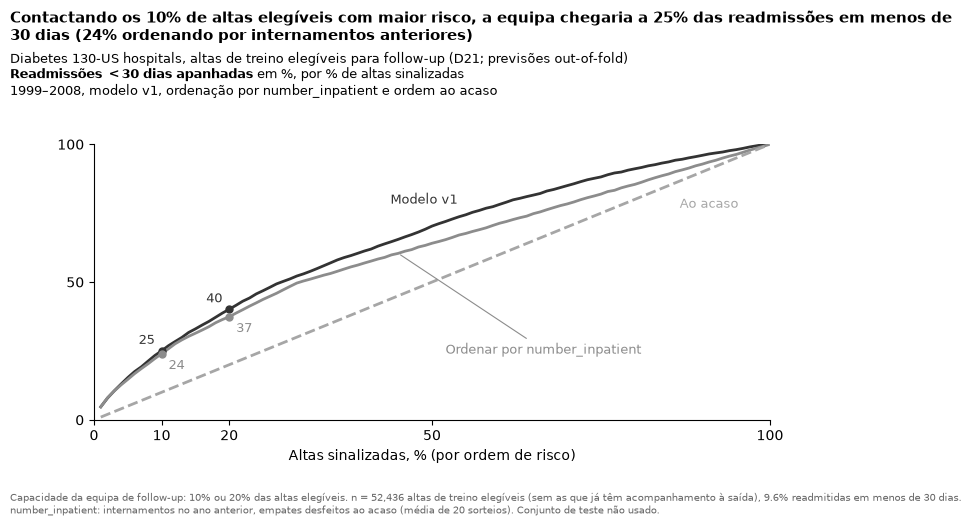

In [8]:
g_model = gains_curve(y_e, oof_e)
g_inp = gains_curve(y_e, X_e["number_inpatient"], n_draws=20)
x10 = g_model.loc[g_model["k"].round(2) == 0.10, "pct_readm_apanhadas"].iat[0]
b10 = g_inp.loc[g_inp["k"].round(2) == 0.10, "pct_readm_apanhadas"].iat[0]

fig, ax = plt.subplots(figsize=(8, 5.2))
g_rand = pd.DataFrame({"k": g_model["k"], "pct_readm_apanhadas": 100 * g_model["k"]})
# (curva, rótulo, cor, estilo, posição do rótulo junto à linha: x em %, deslocamento em pontos)
lines = [(g_model, "Modelo v1", "#333333", "-", 55, (-6, 8), "right"),
         (g_inp, None, "#8c8c8c", "-", None, None, None),
         (g_rand, "Ao acaso", "#a6a6a6", "--", 85, (8, -16), "left")]
at = lambda g, k: g.loc[(100 * g["k"]).round() == k, "pct_readm_apanhadas"].iat[0]
for g, label, color, ls, xk, off, ha in lines:
    ax.plot(100 * g["k"], g["pct_readm_apanhadas"], color=color, ls=ls, lw=2)
    if label:
        ax.annotate(label, (xk, at(g, xk)), xytext=off, textcoords="offset points", ha=ha, fontsize=9, color=color)
# Sem espaço entre as duas linhas cinzentas: rótulo em baixo, com linha de chamada.
ax.annotate("Ordenar por number_inpatient", (45, at(g_inp, 45)), xytext=(52, 24), textcoords="data",
            fontsize=9, color="#8c8c8c", arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=0.8))
for k in (10, 20):
    for g, color, off, ha in [(g_model, "#333333", (-5, 5), "right"), (g_inp, "#8c8c8c", (5, -11), "left")]:
        y = at(g, k)
        ax.plot(k, y, "o", color=color, ms=5)
        ax.annotate(f"{y:.0f}", (k, y), xytext=off, textcoords="offset points", ha=ha, fontsize=9, color=color)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xticks([0, 10, 20, 50, 100]); ax.set_yticks([0, 50, 100])
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Altas sinalizadas, % (por ordem de risco)")
fig.text(0.02, 0.98, f"Contactando os 10% de altas elegíveis com maior risco, a equipa chegaria a {x10:.0f}% das readmissões "
         f"em menos de 30 dias ({b10:.0f}% ordenando por internamentos anteriores)",
         fontsize=10.5, fontweight="bold", va="top", wrap=True)
fig.text(0.02, 0.90, "Diabetes 130-US hospitals, altas de treino elegíveis para follow-up (D21; previsões out-of-fold)\n"
         r"$\bf{Readmissões\ <30\ dias\ apanhadas}$ em %, por % de altas sinalizadas" "\n"
         "1999–2008, modelo v1, ordenação por number_inpatient e ordem ao acaso", fontsize=9, va="top")
fig.text(0.02, 0.01, f"Capacidade da equipa de follow-up: 10% ou 20% das altas elegíveis. n = {len(oof_e):,} altas de treino elegíveis (sem as que já têm acompanhamento à saída), "
         f"{y_e.mean():.1%} readmitidas em menos de 30 dias.\n"
         "number_inpatient: internamentos no ano anterior, empates desfeitos ao acaso (média de 20 sorteios). "
         "Conjunto de teste não usado.", fontsize=7.5, color="#666666")
fig.subplots_adjust(top=0.72, bottom=0.19, right=0.97)
fig.savefig(FIG / "gains_curve_v1.png", dpi=150)
plt.show()

## Calibração: o risco estimado bate certo? (D22)

A pergunta tem duas partes: **qual o risco** e que prioridade. Para mostrar o score como risco, o risco previsto
tem de coincidir com as readmissões observadas. Decis das OOF (grupos de 10% das altas, do menor para o maior
risco), em todas as altas e só nas elegíveis. Sem calibração isotónica/Platt (D19): só se verifica.

In [9]:
from src.models.evaluate import calibration_table

calib = pd.concat({"todas": calibration_table(data.y_train, scores),
                   "elegiveis": calibration_table(y_e, oof_e)}, names=["altas"])
calib.to_csv(ROOT / "reports" / "calibration_v1.csv")
for name, t in calib.groupby(level="altas"):
    print(f"{name}: maior diferença {t['diferenca'].abs().max():.2%}; "
          f"média prevista {(t['risco_previsto'] * t['n']).sum() / t['n'].sum():.2%} "
          f"contra observada {(t['observado'] * t['n']).sum() / t['n'].sum():.2%}")
calib.round(3)

elegiveis: maior diferença 0.85%; média prevista 9.55% contra observada 9.56%
todas: maior diferença 0.60%; média prevista 11.24% contra observada 11.34%


n  risco_previsto  observado  diferenca
altas     grupo                                            
todas     1      8005           0.036      0.040     -0.004
          2      8004           0.052      0.052     -0.001
          3      8004           0.064      0.068     -0.004
          4      8004           0.075      0.081     -0.006
          5      8004           0.087      0.084      0.003
          6      8004           0.100      0.099      0.001
          7      8004           0.116      0.118     -0.002
          8      8004           0.138      0.140     -0.002
          9      8004           0.173      0.173      0.001
          10     8004           0.283      0.280      0.003
elegiveis 1      5244           0.033      0.038     -0.005
          2      5244           0.047      0.047     -0.000
          3      5243           0.056      0.058     -0.003
          4      5244           0.064      0.065     -0.001
          5      5243           0.073      0.075     -0.002
          6      5244           0.083      0.086     -0.003
          7      5243           0.095      0.087      0.008
          8      5244           0.113      0.115     -0.002
          9      5243           0.144      0.144      0.000
          10     5244           0.247      0.239      0.008

## 3.6 Avaliação final no teste (uma vez)

Só depois de fechadas F2·2, P12 e o tuning. Com os thresholds do `config.json` (B6): reportar a fração de altas elegíveis (D21) realmente sinalizada no teste e assinalar na coluna `note` se diferir de k em mais de 1 pp.

In [10]:
# from src.models.train import fit_final, load_model
# bundle = load_model()
# test_elig = follow_up_eligible(data.X_test).to_numpy()  # D21: só altas elegíveis
# test_scores = predict_scores(bundle["model"], data.X_test)[test_elig]
# for k in (10, 20):
#     share = (test_scores >= bundle[f"threshold_k{k}"]).mean()
#     print(k, share, "ATENÇÃO" if abs(share - k / 100) > 0.01 else "")